<a href="https://colab.research.google.com/github/Arif-Khan001/E-commerce-Profitability-Pipeline/blob/main/ETL_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import logging
import time
import numpy as np
import pandas as pd
from sqlalchemy import create_engine, text

In [5]:
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)
logger = logging.getLogger(__name__)
logger.info("Environment and logger initialized successfully.")

In [9]:
file_path = '/content/drive/MyDrive/sales_raw_500.xlsx'

try:
    df_raw = pd.read_excel(file_path)
    logger.info(f"Loaded raw dataset successfully. Shape: {df.shape}")
except Exception as e:
    logger.error(f"Failed to load file: {e}")
    raise

df.head()

,Order_ID,Order_Date,Customer,Region,Product,Sales,Cost
0,1001,2023-01-13,Rohit,South,Mobile,23289,19118
1,1002,2023-10-07,Aman,West,Laptop,8905,5593
2,1003,2023-11-05,Rahul,South,Monitor,59987,39959
3,1004,2024-02-19,Rahul,South,Printer,49597,33892
4,1005,2024-01-26,Anjali,North,Laptop,54797,34468


In [11]:
expected_columns = {'Order_ID', 'Order_Date', 'Customer', 'Region', 'Product', 'Sales', 'Cost'}
missing_cols = expected_columns - set(df_raw.columns)

if missing_cols:
    raise ValueError(f"Schema drift detected! Missing columns: {missing_cols}")
else:
    logger.info("Schema integrity check passed. All required columns are present.")

In [12]:
initial_rows = len(df_raw)
df_cleaned = df_raw.drop_duplicates().copy()
duplicates_removed = initial_rows - len(df_cleaned)

logger.info(f"Removed {duplicates_removed} duplicate records. Remaining rows: {len(df_cleaned)}")

In [15]:
df_cleaned['Order_Date'] = pd.to_datetime(df_cleaned['Order_Date'], errors='coerce')

pre_na_count = len(df_cleaned)
df_cleaned = df_cleaned.dropna(subset=['Order_Date']).copy()

logger.info(f"Dropped {pre_na_count - len(df_cleaned)} rows with invalid or missing dates.")

In [16]:
for col in ['Sales', 'Cost']:
    df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce').fillna(0.0)
    df_cleaned[col] = df_cleaned[col].apply(lambda x: max(0.0, float(x)))

logger.info(f"Numeric sanitation complete. Clean row count: {len(df_cleaned)}")

In [17]:
df_cleaned['Profit'] = df_cleaned['Sales'] - df_cleaned['Cost']

df_cleaned['Profit_Margin_%'] = np.where(
    df_cleaned['Sales'] > 0,
    np.round((df_cleaned['Profit'] / df_cleaned['Sales']) * 100, 2),
    0.0
)

df_cleaned[['Sales', 'Cost', 'Profit', 'Profit_Margin_%']].head()

,Sales,Cost,Profit,Profit_Margin_%
0,23289.0,19118.0,4171.0,17.91
1,8905.0,5593.0,3312.0,37.19
2,59987.0,39959.0,20028.0,33.39
3,49597.0,33892.0,15705.0,31.67
4,54797.0,34468.0,20329.0,37.10


In [20]:
df_cleaned['Year'] = df_cleaned['Order_Date'].dt.year
df_cleaned['Month'] = df_cleaned['Order_Date'].dt.month
df_cleaned['Quarter'] = df_cleaned['Order_Date'].dt.to_period('Q').astype(str)
df_cleaned['Day_of_Week'] = df_cleaned['Order_Date'].dt.day_name()

df_cleaned[['Order_Date', 'Year', 'Quarter', 'Month', 'Day_of_Week']].head()

,Order_Date,Year,Quarter,Month,Day_of_Week
0,2023-01-13,2023,2023Q1,1,Friday
1,2023-10-07,2023,2023Q4,10,Saturday
2,2023-11-05,2023,2023Q4,11,Sunday
3,2024-02-19,2024,2024Q1,2,Monday
4,2024-01-26,2024,2024Q1,1,Friday


In [22]:
df_cleaned['Order_Tier'] = pd.cut(
    df_cleaned['Sales'],
    bins=[-np.inf, 250, 1000, np.inf],
    labels=['Standard', 'Mid-Value', 'High-Value']
)

df_cleaned[['Order_ID', 'Sales', 'Order_Tier']].head()

,Order_ID,Sales,Order_Tier
0,1001,23289.0,High-Value
1,1002,8905.0,High-Value
2,1003,59987.0,High-Value
3,1004,49597.0,High-Value
4,1005,54797.0,High-Value


In [23]:
print("=" * 50)
print("DATA QUALITY AUDIT & ETL SUMMARY")
print("=" * 50)
print(f"Total Processed Rows   : {len(df_cleaned)}")
print(f"Total Sales Volume     : ${df_cleaned['Sales'].sum():,.2f}")
print(f"Total Profit Generated : ${df_cleaned['Profit'].sum():,.2f}")
print(f"Average Profit Margin  : {df_cleaned['Profit_Margin_%'].mean():.2f}%")
print(f"Active Regions         : {list(df_cleaned['Region'].unique())}")
print(f"Total Missing Values   : {df_cleaned.isnull().sum().sum()}")
print("=" * 50)

DATA QUALITY AUDIT & ETL SUMMARY
Total Processed Rows   : 482
Total Sales Volume     : $19,809,635.00
Total Profit Generated : $4,992,154.00
Average Profit Margin  : 25.09%
Active Regions         : ['South', 'West', 'North', 'East']
Total Missing Values   : 0


In [24]:
output_csv = "sales_clean.csv"
df_cleaned.to_csv(output_csv, index=False)
logger.info(f"Saved cleaned dataset to '{output_csv}'.")

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Set global visual theme and figure formatting
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

logger.info("Matplotlib and Seaborn visualization environment configured.")

In [30]:
# 1. If 'df_cleaned' was used in earlier cells, sync it with 'df'
if 'df_cleaned' in locals() and 'Profit' in df_cleaned.columns and 'Profit' not in df.columns:
    df = df_cleaned.copy()

# 2. Ensure all engineered columns exist on 'df'
if 'Profit' not in df.columns:
    df['Sales'] = pd.to_numeric(df['Sales'], errors='coerce').fillna(0.0)
    df['Cost'] = pd.to_numeric(df['Cost'], errors='coerce').fillna(0.0)
    df['Profit'] = df['Sales'] - df['Cost']

if 'Profit_Margin_%' not in df.columns:
    df['Profit_Margin_%'] = np.where(
        df['Sales'] > 0,
        np.round((df['Profit'] / df['Sales']) * 100, 2),
        0.0
    )

if 'Order_Tier' not in df.columns:
    df['Order_Tier'] = pd.cut(
        df['Sales'],
        bins=[-np.inf, 250, 1000, np.inf],
        labels=['Standard', 'Mid-Value', 'High-Value']
    )

df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
df = df.dropna(subset=['Order_Date']).copy()

# 3. Set global visual theme and figure formatting
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

print("Columns currently in df:", list(df.columns))

Columns currently in df: ['Order_ID', 'Order_Date', 'Customer', 'Region', 'Product', 'Sales', 'Cost', 'Profit', 'Profit_Margin_%', 'Year', 'Month', 'Quarter', 'Day_of_Week', 'Order_Tier']


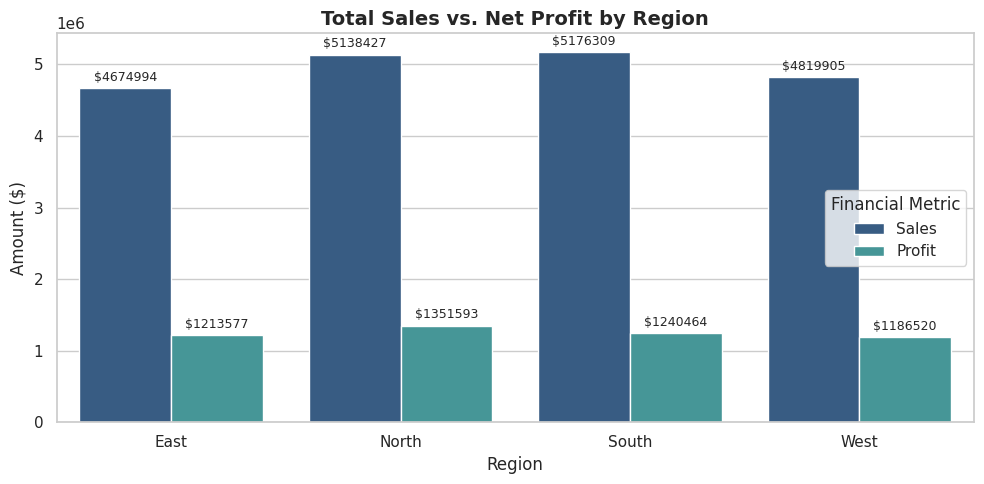

In [31]:
# Aggregate Sales and Profit by Region
region_summary = df.groupby('Region')[['Sales', 'Profit']].sum().reset_index()
region_melted = region_summary.melt(id_vars='Region', var_name='Metric', value_name='Amount')

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=region_melted, x='Region', y='Amount', hue='Metric', palette=['#2b5c8f', '#38a3a5'])

plt.title('Total Sales vs. Net Profit by Region')
plt.xlabel('Region')
plt.ylabel('Amount ($)')
plt.legend(title='Financial Metric')

# Add value labels on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt='$%.0f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

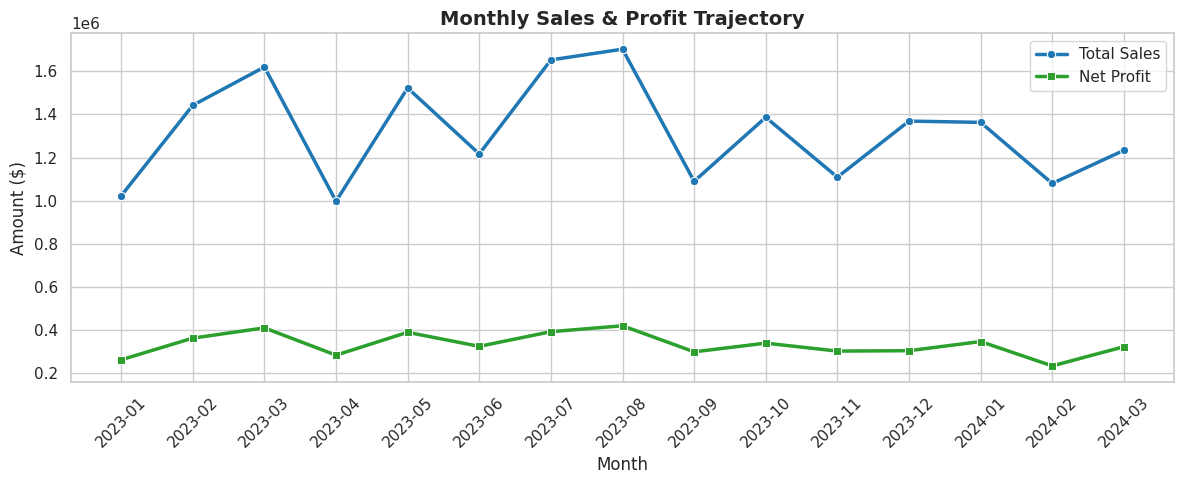

In [33]:
# Group by Year-Month to trace chronological performance
df['Year_Month'] = df['Order_Date'].dt.to_period('M').astype(str)
monthly_trend = df.groupby('Year_Month')[['Sales', 'Profit']].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_trend, x='Year_Month', y='Sales', marker='o', linewidth=2.5, label='Total Sales', color='#1f77b4')
sns.lineplot(data=monthly_trend, x='Year_Month', y='Profit', marker='s', linewidth=2.5, label='Net Profit', color='#2ca02c')

plt.title('Monthly Sales & Profit Trajectory')
plt.xlabel('Month')
plt.ylabel('Amount ($)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# Drop temporary helper column before SQL export if desired
df.drop(columns=['Year_Month'], inplace=True)

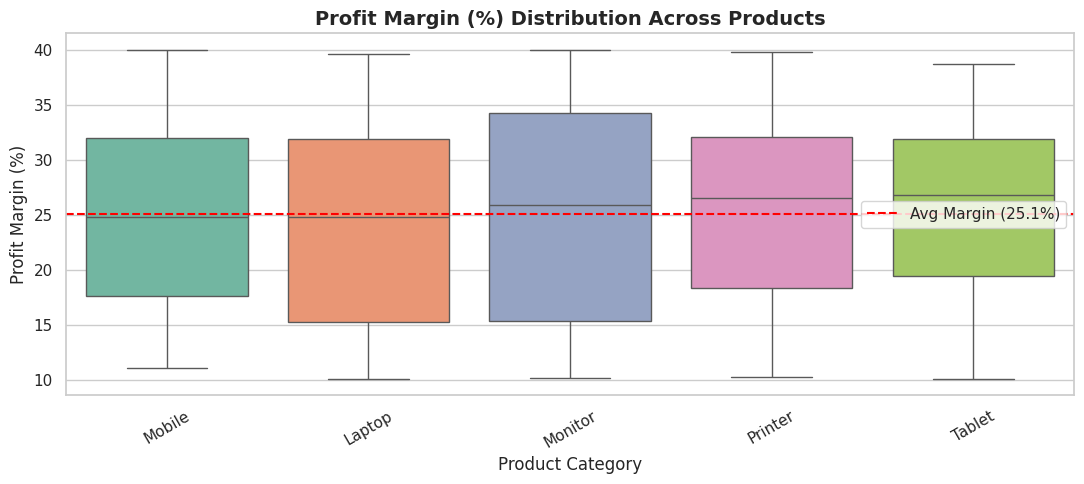

In [34]:
plt.figure(figsize=(11, 5))
sns.boxplot(
    data=df,
    x='Product',
    y='Profit_Margin_%',
    hue='Product',
    palette='Set2',
    legend=False
)

plt.axhline(df['Profit_Margin_%'].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Avg Margin ({df['Profit_Margin_%'].mean():.1f}%)")
plt.title('Profit Margin (%) Distribution Across Products')
plt.xlabel('Product Category')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

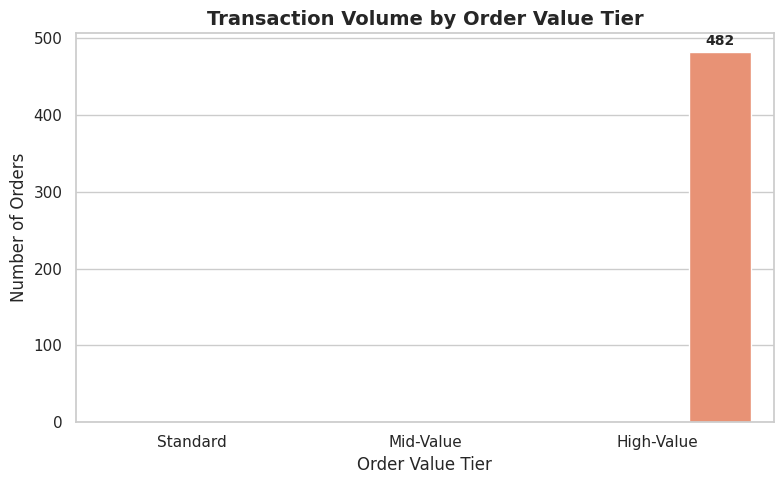

In [35]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x='Order_Tier',
    hue='Order_Tier',
    palette='magma',
    legend=False
)

plt.title('Transaction Volume by Order Value Tier')
plt.xlabel('Order Value Tier')
plt.ylabel('Number of Orders')

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

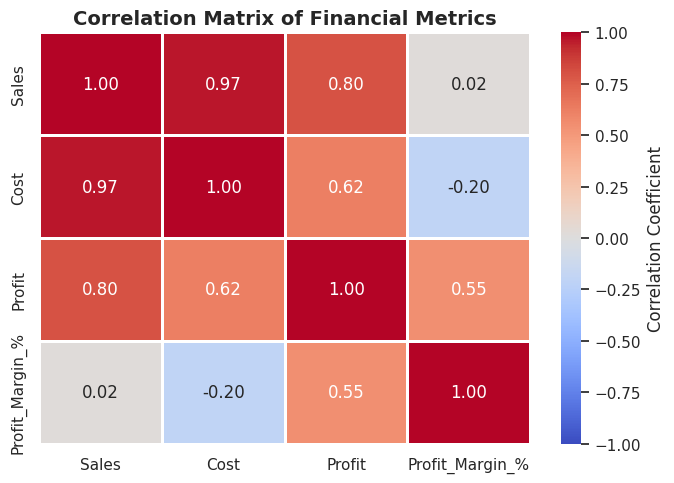

In [36]:
plt.figure(figsize=(7, 5))
numeric_cols = ['Sales', 'Cost', 'Profit', 'Profit_Margin_%']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=1,
    cbar_kws={'label': 'Correlation Coefficient'}
)

plt.title('Correlation Matrix of Financial Metrics')
plt.tight_layout()
plt.show()

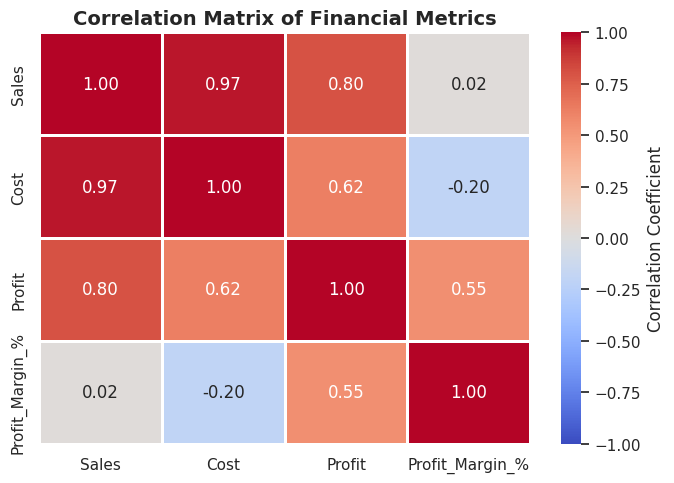

In [37]:
plt.figure(figsize=(7, 5))
numeric_cols = ['Sales', 'Cost', 'Profit', 'Profit_Margin_%']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=1,
    cbar_kws={'label': 'Correlation Coefficient'}
)

plt.title('Correlation Matrix of Financial Metrics')
plt.tight_layout()
plt.show()